
# Assignment 3: SLCM Classification Analysis

## Part 1 – Understand the Classification Problem (15 points)

### 1. Explore the dataset (7 points)

- Load the CSV. Display five rows, the data shape, the column names, and missing-value counts.
- Identify one numerical and one categorical feature.
- Answer: Why must `past_due_rent` be excluded from the input features?


In [34]:

# Load the dataset and display basic information
import pandas as pd

df = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Assignment 3/SLCM_rent_arrears_student_clean.csv")

display(df.head())

print("Dataset shape:", df.shape)

print("Column names:")
print(df.columns)

print("Missing values:")
print(df.isnull().sum())


,record_id,adults_in_household,children_in_household,household_has_65plus,monthly_household_income,income_sources,employment_status,has_housing_voucher,eviction_in_progress,behind_on_utilities,main_reason_behind_on_rent,intake_quarter,monthly_rent,past_due_rent
0,SLCM_0001,1,1,No,293.0,"Food benefits - TANF/SNAP, No income, Other",Unemployed but want to find work,No,I don't know,Yes,Other,2026-Q1,1560.0,3100.0
1,SLCM_0002,0,3,No,2000.0,Child support,Employed,No,I don't know,Yes,Unexpected expense,2026-Q3,1550.0,7300.0
2,SLCM_0003,1,0,No,400.0,Food benefits - TANF/SNAP,Unemployed but want to find work,I don't know,Yes,Yes,Lost a job/had hours cut,2025-Q4,0.0,6000.0
3,SLCM_0004,2,0,No,2500.0,Full-time employment,Unemployed and not looking for work,No,Yes,Yes,Lost a job/had hours cut,2026-Q2,1299.0,2500.0
4,SLCM_0005,1,2,No,14.0,Part-time employment,Employed,No,Yes,No,Unexpected expense,2025-Q4,1105.5,1205.5


Dataset shape: (1754, 14)
Column names:
Index(['record_id', 'adults_in_household', 'children_in_household',
       'household_has_65plus', 'monthly_household_income', 'income_sources',
       'employment_status', 'has_housing_voucher', 'eviction_in_progress',
       'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter',
       'monthly_rent', 'past_due_rent'],
      dtype='object')
Missing values:
record_id                       0
adults_in_household             0
children_in_household           0
household_has_65plus            0
monthly_household_income      108
income_sources                  0
employment_status               0
has_housing_voucher             0
eviction_in_progress            1
behind_on_utilities             7
main_reason_behind_on_rent     16
intake_quarter                  0
monthly_rent                    8
past_due_rent                   0
dtype: int64



**Dataset Exploration:**

The dataset contains 1,754 rows and 14 columns. Some columns have missing values, such as `monthly_household_income` and `monthly_rent`.

- **Numerical feature:** `monthly_household_income`
- **Categorical feature:** `employment_status`

**Why must `past_due_rent` be excluded from the input features?**

We must exclude `past_due_rent` because our target variable `high_arrears` is calculated directly from it. If we include it, the model would already have the information needed to predict the answer. This is called data leakage and would make our results misleading.



### 2. Create the target (8 points)

- Create `high_arrears`: 1 if `past_due_rent` is at least $3,000, otherwise 0.
- Show class counts and one bar chart of `high_arrears`.
- Answer: Which class is larger? Why might accuracy alone be misleading?


Class counts:
high_arrears
0    1210
1     544
Name: count, dtype: int64


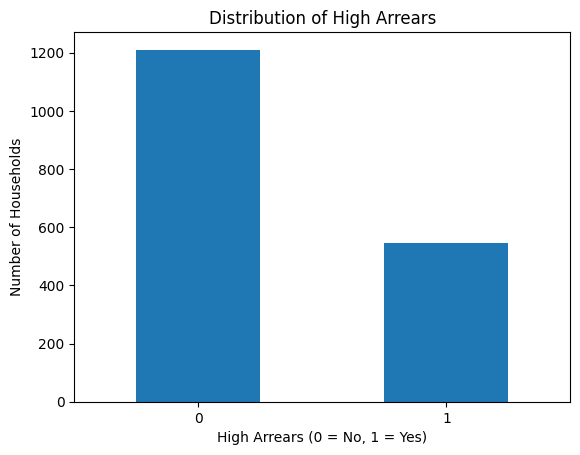

In [35]:

# Create the target variable and display the class distribution
import matplotlib.pyplot as plt

df["high_arrears"] = (df["past_due_rent"] >= 3000).astype(int)

print("Class counts:")
print(df["high_arrears"].value_counts())

# Create a bar chart showing the number of households in each class
df["high_arrears"].value_counts().sort_index().plot(kind="bar")

plt.title("Distribution of High Arrears")
plt.xlabel("High Arrears (0 = No, 1 = Yes)")
plt.ylabel("Number of Households")
plt.xticks(rotation=0)
plt.show()



**Class Distribution:**

The dataset contains 1,210 households in class 0 (less than $3,000 in past-due rent) and 544 households in class 1 ($3,000 or more). Class 0 is larger, meaning most households have less than $3,000 in overdue rent.

**Why might accuracy alone be misleading?**

Accuracy can be misleading because the classes are unbalanced. A model could predict class 0 most of the time and still have a high accuracy, even if it misses many households with high arrears. This is why recall and F1 are also important when evaluating our models.



## Part 2 – Prepare the Data (25 points)

### 3. Select features and split (10 points)

- Create `X` by dropping `record_id`, `past_due_rent`, and `high_arrears`. Set `y = high_arrears`.
- Split the data once into training and testing sets.
- Answer: Why do we keep a separate test set?


In [36]:

# Select the input features and split the data into training and testing sets
from sklearn.model_selection import train_test_split

X = df.drop(columns=["record_id", "past_due_rent", "high_arrears"])
y = df["high_arrears"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)


Training set shape: (1403, 12)
Testing set shape: (351, 12)



**Training and Testing Sets:**

The dataset was split into 80% training data (1,403 rows) and 20% testing data (351 rows). Both sets contain 12 input features.

**Why do we keep a separate test set?**

We keep a separate test set to evaluate how well our model performs on data it has never seen before. If we test the model on the same data used for training, the results might be misleading because the model could have memorized patterns from that data. A separate test set helps us measure how well the model can make predictions on new data.



### 4. Build one reusable preprocessor (15 points)

- Identify numerical and categorical columns using `select_dtypes`.
- **Numerical:** Fill missing values using the median and apply `StandardScaler`.
- **Categorical:** Fill missing values using `most_frequent` and apply `OneHotEncoder(handle_unknown="ignore")`.
- Combine both preprocessing pipelines using `ColumnTransformer`.
- Answer: Why is scaling helpful for KNN and SVC?


In [37]:

# Identify numerical and categorical columns and create preprocessing pipelines
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

num_cols = X.select_dtypes(include=["int64", "float64"]).columns
cat_cols = X.select_dtypes(include=["object", "category"]).columns

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", num_pipeline, num_cols),
    ("cat", cat_pipeline, cat_cols)
])

print("Numerical columns:", list(num_cols))
print("Categorical columns:", list(cat_cols))


Numerical columns: ['adults_in_household', 'children_in_household', 'monthly_household_income', 'monthly_rent']
Categorical columns: ['household_has_65plus', 'income_sources', 'employment_status', 'has_housing_voucher', 'eviction_in_progress', 'behind_on_utilities', 'main_reason_behind_on_rent', 'intake_quarter']



**Why is scaling helpful for KNN and SVC?**

Scaling is important because KNN and SVC are sensitive to the size of numerical features. For example, household income might have much larger values than household size, so it could have more influence on the model. StandardScaler puts numerical features on a similar scale so that features with larger values do not automatically dominate the predictions.



## Part 3 – Train and Compare Five Models (45 points)

### 5. Train the five classifiers (20 points)

Build five pipelines using the same preprocessor and training set:

- **Logistic Regression:** `LogisticRegression(max_iter=1000)`
- **KNN:** `KNeighborsClassifier(n_neighbors=5)`
- **Decision Tree:** `DecisionTreeClassifier(max_depth=5, random_state=42)`
- **Random Forest:** `RandomForestClassifier(n_estimators=100, random_state=42)`
- **Support Vector Classifier:** `SVC()`

Fit each pipeline and report test accuracy, recall, and F1 for class 1. Use a short, repeated code pattern. A loop or custom function is not required.


In [38]:

# Import the classification models and evaluation metrics
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, recall_score, f1_score


In [39]:

# Train and evaluate the Logistic Regression model
lr_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", LogisticRegression(max_iter=1000))
])

lr_model.fit(X_train, y_train)
lr_pred = lr_model.predict(X_test)

print("Logistic Regression")
print("Accuracy:", accuracy_score(y_test, lr_pred))
print("Recall:", recall_score(y_test, lr_pred))
print("F1:", f1_score(y_test, lr_pred))


Logistic Regression
Accuracy: 0.6951566951566952
Recall: 0.30275229357798167
F1: 0.3815028901734104


In [40]:

# Train and evaluate the KNN model
knn_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_model.fit(X_train, y_train)
knn_pred = knn_model.predict(X_test)

print("KNN")
print("Accuracy:", accuracy_score(y_test, knn_pred))
print("Recall:", recall_score(y_test, knn_pred))
print("F1:", f1_score(y_test, knn_pred))


KNN
Accuracy: 0.6809116809116809
Recall: 0.3761467889908257
F1: 0.422680412371134


In [41]:

# Train and evaluate the Decision Tree model
dt_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", DecisionTreeClassifier(max_depth=5, random_state=42))
])

dt_model.fit(X_train, y_train)
dt_pred = dt_model.predict(X_test)

print("Decision Tree")
print("Accuracy:", accuracy_score(y_test, dt_pred))
print("Recall:", recall_score(y_test, dt_pred))
print("F1:", f1_score(y_test, dt_pred))


Decision Tree
Accuracy: 0.6951566951566952
Recall: 0.3302752293577982
F1: 0.4022346368715084


In [42]:

# Train and evaluate the Random Forest model
rf_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", RandomForestClassifier(n_estimators=100, random_state=42))
])

rf_model.fit(X_train, y_train)
rf_pred = rf_model.predict(X_test)

print("Random Forest")
print("Accuracy:", accuracy_score(y_test, rf_pred))
print("Recall:", recall_score(y_test, rf_pred))
print("F1:", f1_score(y_test, rf_pred))


Random Forest
Accuracy: 0.7037037037037037
Recall: 0.3211009174311927
F1: 0.40229885057471265


In [43]:

# Train and evaluate the SVC model
svc_model = Pipeline([
    ("preprocessor", preprocessor),
    ("model", SVC())
])

svc_model.fit(X_train, y_train)
svc_pred = svc_model.predict(X_test)

print("SVC")
print("Accuracy:", accuracy_score(y_test, svc_pred))
print("Recall:", recall_score(y_test, svc_pred))
print("F1:", f1_score(y_test, svc_pred))


SVC
Accuracy: 0.7065527065527065
Recall: 0.22935779816513763
F1: 0.32679738562091504



### 6. Compare the models (10 points)

- Put the test results in one table with the columns: Model, Accuracy, Recall, F1.
- Create one confusion matrix for the model with the highest test F1.
- Answer: Which model catches the highest proportion of high-arrears households? What does a missed case mean for SLCM?


In [44]:

# Create a table comparing the performance of all five models
results = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "Decision Tree", "Random Forest", "SVC"],
    "Accuracy": [
        accuracy_score(y_test, lr_pred),
        accuracy_score(y_test, knn_pred),
        accuracy_score(y_test, dt_pred),
        accuracy_score(y_test, rf_pred),
        accuracy_score(y_test, svc_pred)
    ],
    "Recall": [
        recall_score(y_test, lr_pred),
        recall_score(y_test, knn_pred),
        recall_score(y_test, dt_pred),
        recall_score(y_test, rf_pred),
        recall_score(y_test, svc_pred)
    ],
    "F1": [
        f1_score(y_test, lr_pred),
        f1_score(y_test, knn_pred),
        f1_score(y_test, dt_pred),
        f1_score(y_test, rf_pred),
        f1_score(y_test, svc_pred)
    ]
})

display(results.round(3))


,Model,Accuracy,Recall,F1
0,Logistic Regression,0.695,0.303,0.382
1,KNN,0.681,0.376,0.423
2,Decision Tree,0.695,0.330,0.402
3,Random Forest,0.704,0.321,0.402
4,SVC,0.707,0.229,0.327


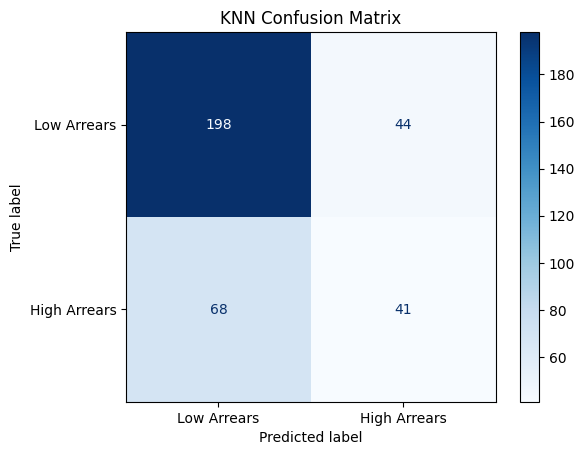

In [45]:

# Display the confusion matrix for KNN, the model with the highest F1 score
from sklearn.metrics import ConfusionMatrixDisplay

ConfusionMatrixDisplay.from_predictions(
    y_test,
    knn_pred,
    display_labels=["Low Arrears", "High Arrears"],
    cmap="Blues"
)

plt.title("KNN Confusion Matrix")
plt.show()



**Model Comparison:**

KNN has the highest recall (37.6%) and F1 score (0.423), meaning it identifies the largest proportion of households with high arrears among the five models. Although SVC has the highest accuracy (70.7%), its recall is lower, so it misses more households with high arrears.

**What does a missed case mean for SLCM?**

A missed case is called a false negative, which happens when a household actually has $3,000 or more in overdue rent but the model predicts otherwise. For SLCM, this could mean overlooking a household that might need financial assistance.



### 7. Try a small GridSearchCV (15 points)

- Tune only two models on the training set with `cv=3` and `scoring="f1"`.
- For KNN, try `n_neighbors = [3, 5, 7]`.
- For Random Forest, try `max_depth = [3, 5, None]` (keep `n_estimators=100`).
- Print `best_params_` and `best_score_` for each search. No extra charts or second search are needed.
- Answer: Which has the higher best cross-validation F1? Why is GridSearchCV fitted on training data only?


In [46]:

# Find the best number of neighbors for KNN using GridSearchCV
from sklearn.model_selection import GridSearchCV

knn_params = {
    "model__n_neighbors": [3, 5, 7]
}

knn_grid = GridSearchCV(
    knn_model,
    knn_params,
    cv=3,
    scoring="f1"
)

knn_grid.fit(X_train, y_train)

print("Best KNN parameters:", knn_grid.best_params_)
print("Best KNN cross-validation F1:", knn_grid.best_score_)


Best KNN parameters: {'model__n_neighbors': 7}
Best KNN cross-validation F1: 0.4854649923374277


In [47]:

# Find the best maximum tree depth for Random Forest using GridSearchCV
rf_params = {
    "model__max_depth": [3, 5, None]
}

rf_grid = GridSearchCV(
    rf_model,
    rf_params,
    cv=3,
    scoring="f1"
)

rf_grid.fit(X_train, y_train)

print("Best Random Forest parameters:", rf_grid.best_params_)
print("Best Random Forest cross-validation F1:", rf_grid.best_score_)


Best Random Forest parameters: {'model__max_depth': None}
Best Random Forest cross-validation F1: 0.4574743145651916



**GridSearchCV Results:**

GridSearchCV found that the best number of neighbors for KNN is 7, with a cross-validation F1 score of 0.4855. For Random Forest, the best maximum depth is None, with an F1 score of 0.4575. KNN performed better during cross-validation.

**Why is GridSearchCV fitted on training data only?**

GridSearchCV uses the training data to test different parameters and find the best settings. We keep the test data separate so we can evaluate the model on data it has never seen before. Using the test data for tuning could lead to overly optimistic results and would not give us a fair evaluation.



## Part 4 – Explain the Results (15 points)

### 8. Interpret your comparison (8 points)

- In 4–5 sentences, identify the most promising model based on your results.
- Explain your choice using F1 and recall, not accuracy alone.
- Did a more complex model necessarily perform better?
- What types of errors should SLCM pay attention to?



**Model Comparison and Interpretation:**

KNN is the most promising model because it has the highest F1 score (0.423) and recall (0.376), meaning it identifies more high-arrears households than the other models. Although SVC has the highest accuracy (0.707), its recall is much lower (0.229), so it misses more households with high arrears. The more complex models, such as Random Forest, did not necessarily perform better than KNN. SLCM should pay special attention to false negatives because these represent households with high arrears that the model fails to identify. False positives are also important because they could lead SLCM to spend time reviewing households that do not actually have high arrears.



### 9. Recommendation to SLCM (7 points)

- Write 4–5 sentences for a non-technical SLCM audience.
- Explain what you tried to predict, how well the selected model performed, one practical insight, and one limitation.
- State that a prediction is not proof of cause and must not be used alone to decide eligibility for assistance.



**Recommendation to SLCM:**

We tested five machine learning models to predict which households have $3,000 or more in past-due rent using household and housing information. KNN was the most promising model, with an F1 score of 0.423 and a recall of 37.6%, meaning it correctly identified about 38% of households with high arrears. These results suggest that household information can help identify some households who may need financial assistance, but the model still misses many cases. Because of this limitation, SLCM should use the predictions only as an additional tool to support its decisions. A prediction does not prove what causes rent arrears and should never be used alone to determine eligibility for assistance.
